# Калибровка датчика давления с помощью реперных точек

Цель: по известным давлениям фазовых переходов в нескольких материалах (реперным точкам) определить функцию преобразования выходного напряжения 
тензодатчика (мВ) в истинное давление (Па).

Исходные данные: для каждого материала записаны временные ряды сопротивления образца при ступенчатом изменении давления. 
Файлы получены с измерительной установки в формате `.xls`.

## Структура исходных данных:

Каждый файл содержит колонки:

`Time` --- время, показывающее момент получания значения сопротивления,

`OHM` --- сопротивление образца, в Ом

колонка со значением давления, в В (заполнена только первая ячейка для группы значений сопротивления, измеренных при одном давлении),

технические столбцы.

Пример данных:

In [58]:
import xlrd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scripts.data_processing import inp, fill_press, avg_last, save

file_name = 'ZnS.xls'

book = xlrd.open_workbook(Path('data/raw') / file_name)
sheet = book.sheet_by_index(0)

data = []
for row in range(sheet.nrows):
    data.append(sheet.row_values(row))


df = pd.DataFrame(data[1:], columns=data[0])

df.head()

,Time,OHM,,,Start Time,46209.534444
0,46209.534468,223943.984,0.1,,Interval,0.000058
1,46209.534583,224927.344,,,,
2,46209.534641,228039.744,,,Samples Completed,1117.0
3,46209.534699,236399.024,,,,
4,46209.534757,236618.128,,,Last Point on Chart,1117.0


In [59]:
df.iloc[85:92]

,Time,OHM,,,Start Time,46209.534444
85,46209.539444,359420.544,,,,
86,46209.539502,367092.480,,,,
87,46209.539560,365200.640,,,,
88,46209.540139,381622.400,0.3,,,
89,46209.540197,371414.880,,,,
90,46209.540255,377444.672,,,,
91,46209.540313,376585.920,,,,


колонка `Time` читается не правильно (проблема с форматом?), она, а так же техническая информация из 4 и 5 колонок не нужны для дальнейшей обработки

## Обработка данных

Обработка всех файлов с зависимостями сопротивления от давления производится с помощью цикла, который:

читает файл в формате .xls
заполняет пропущенные значения давления
усредняет последние 25 значений сопротивления
сохраняет результат в файл excel

In [60]:
materials = {
    'ZnS': 'ZnS.xls',
    'CdS': 'CdS.xls',
    'KBr': 'KBr.xls',
    'NaCl': 'NaCl.xls',
    'Bi2Te3': 'Bi2Te3.xls',
    'dwcnt': 'dwcnt.xls'
}

fill_direction = 'up' #заполнена только первая ячейка для группы значений сопротивления
#fill_direction = 'dn' #заполнена только последняя ячейка для группы значений сопротивления

processed = {}

for name, file_name in materials.items():
    df = inp(file_name) #чтение файла, остаются только необходимые значения
    df = fill_press(df, fill_direction) #обработка пропусков
    df = avg_last(df) #усреднение значений
    processed[name] = df
    save(df, file_name) #сохраняем результат

## Построение графика

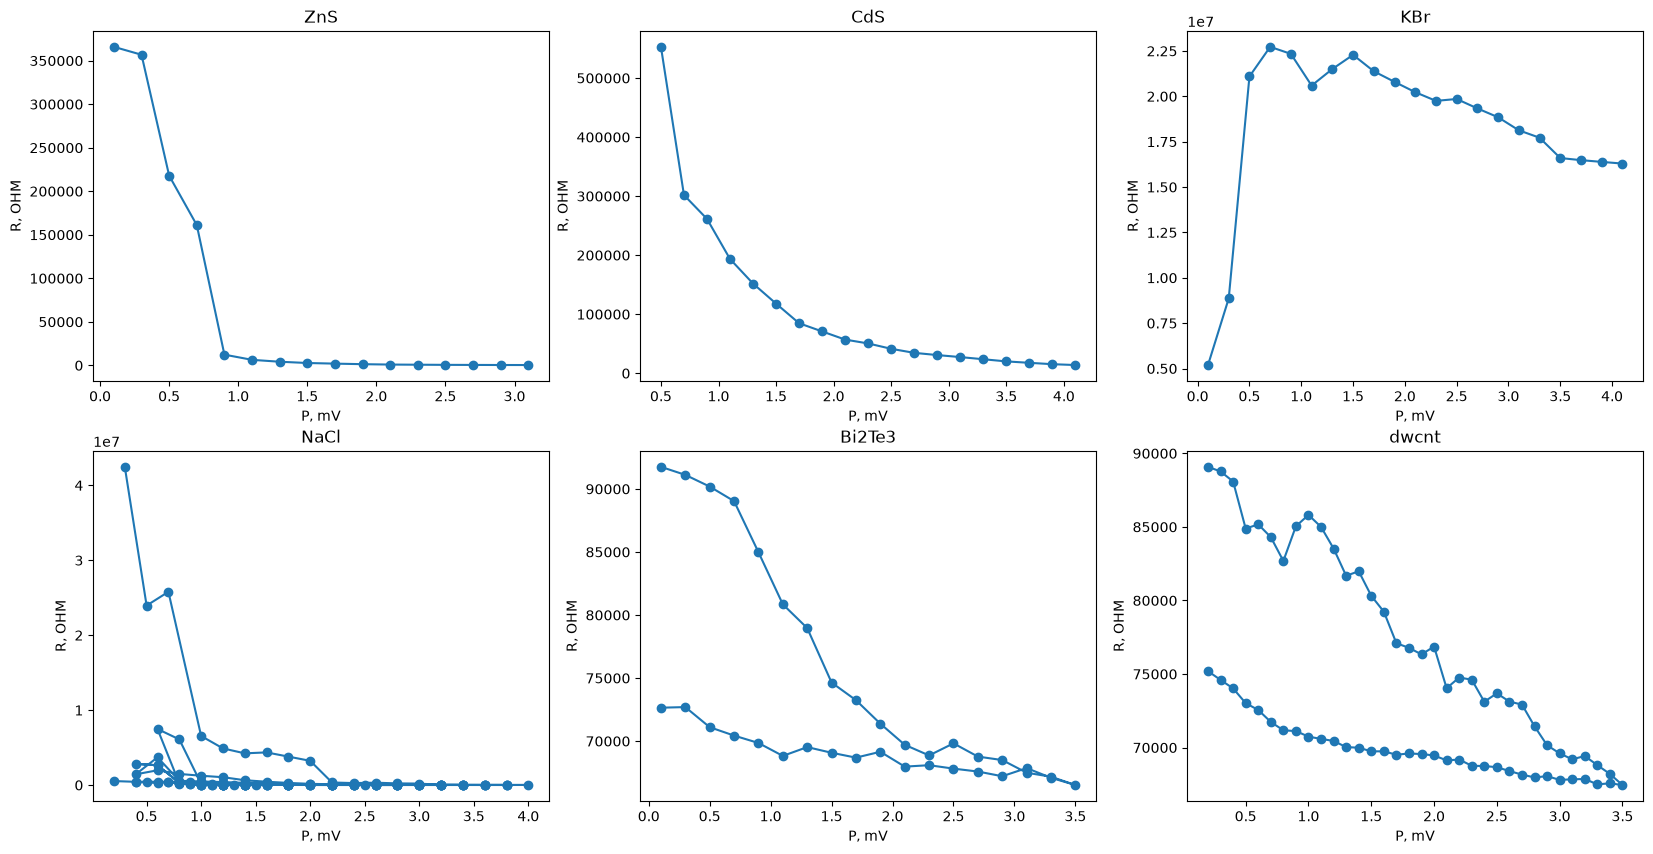

In [74]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20, 10))


axes[0,0].plot(processed['ZnS']['P, mV'], processed['ZnS']['R, OHM'], marker='o')
axes[0,0].set_xlabel('P, mV')
axes[0,0].set_ylabel('R, OHM')
axes[0,0].set_title('ZnS')

axes[0,1].plot(processed['CdS']['P, mV'], processed['CdS']['R, OHM'], marker='o')
axes[0,1].set_xlabel('P, mV')
axes[0,1].set_ylabel('R, OHM')
axes[0,1].set_title('CdS')

axes[0,2].plot(processed['KBr']['P, mV'], processed['KBr']['R, OHM'], marker='o')
axes[0,2].set_xlabel('P, mV')
axes[0,2].set_ylabel('R, OHM')
axes[0,2].set_title('KBr')

axes[1,0].plot(processed['NaCl']['P, mV'], processed['NaCl']['R, OHM'], marker='o')
axes[1,0].set_xlabel('P, mV')
axes[1,0].set_ylabel('R, OHM')
axes[1,0].set_title('NaCl')

axes[1,1].plot(processed['Bi2Te3']['P, mV'], processed['Bi2Te3']['R, OHM'], marker='o')
axes[1,1].set_xlabel('P, mV')
axes[1,1].set_ylabel('R, OHM')
axes[1,1].set_title('Bi2Te3')

axes[1,2].plot(processed['dwcnt']['P, mV'], processed['dwcnt']['R, OHM'], marker='o')
axes[1,2].set_xlabel('P, mV')
axes[1,2].set_ylabel('R, OHM')
axes[1,2].set_title('dwcnt')

#graph_file = f"graph_averaged.png"
#plt.savefig(graph_file)

plt.show()